In [1]:
!pip install pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 56.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 81.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 106.4 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1


In [2]:
"""
Data layer for the QAE novel-species detection pipeline.

NOTE: This uses SYNTHETIC placeholder sequences so the pipeline runs
end-to-end right now. Replace `REFERENCE_SEQUENCES` with real sequences
pulled from BOLD (COI) or SILVA (16S/18S) for your actual waterborne
microorganism problem statement before the demo.
"""

import random

random.seed(42)

BASES = "ATCG"


def _mutate(seq, rate=0.03):
    """Introduce random substitutions to simulate a noisy read of a
    reference sequence (stand-in for a real read simulator)."""
    seq = list(seq)
    for i in range(len(seq)):
        if random.random() < rate:
            seq[i] = random.choice(BASES)
    return "".join(seq)


def _random_seq(length):
    return "".join(random.choice(BASES) for _ in range(length))


# --- Known/reference species: each has one "true" barcode sequence ---
# In the real pipeline these come from BOLD/SILVA with verified species labels.
KNOWN_SPECIES = {
    "Vorticella_sp": _random_seq(120),
    "Paramecium_sp": _random_seq(120),
    "Euglena_sp": _random_seq(120),
    "Rotifer_sp": _random_seq(120),
    "Vibrio_sp": _random_seq(120),
}


def generate_known_samples(n_per_species=40, mutation_rate=0.03):
    """Simulate multiple noisy reads per known species (training/reference set)."""
    samples = []
    labels = []
    for species, ref_seq in KNOWN_SPECIES.items():
        for _ in range(n_per_species):
            samples.append(_mutate(ref_seq, rate=mutation_rate))
            labels.append(species)
    return samples, labels


def generate_novel_samples(n=20):
    """Simulate sequences from species NOT in the reference DB at all
    (stand-in for undocumented/novel species eDNA reads)."""
    return [_random_seq(120) for _ in range(n)]


if __name__ == "__main__":
    known_seqs, known_labels = generate_known_samples()
    novel_seqs = generate_novel_samples()
    print(f"Known samples: {len(known_seqs)} across {len(set(known_labels))} species")
    print(f"Novel samples: {len(novel_seqs)}")
    print("Example known sequence:", known_seqs[0][:40], "...")
    print("Example novel sequence:", novel_seqs[0][:40], "...")


Known samples: 200 across 5 species
Novel samples: 20
Example known sequence: AACTTTAAGAAATTATGTGCATGCCTTCATGACCCAGAGA ...
Example novel sequence: TCAGCCGCGGCAACACGGCTAAGCCGTTGGGCGTATGAGT ...


In [3]:
"""
Feature extraction: DNA sequence -> fixed-length numeric vector.
Plain functions only, no classes.
"""

import itertools
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler

BASES = "ATCG"


def build_kmer_vocab(k):
    return ["".join(p) for p in itertools.product(BASES, repeat=k)]


def kmer_frequency_vector(seq, k, vocab):
    counts = {kmer: 0 for kmer in vocab}
    for i in range(len(seq) - k + 1):
        kmer = seq[i:i + k]
        if kmer in counts:
            counts[kmer] += 1
    total = sum(counts.values())
    if total == 0:
        return np.zeros(len(vocab))
    return np.array([counts[kmer] / total for kmer in vocab])


def raw_kmer_matrix(sequences, k, vocab):
    return np.array([kmer_frequency_vector(s, k, vocab) for s in sequences])


def fit_feature_pipeline(sequences, k=3, n_qubits=4):
    """Fit on reference/known sequences. Returns the vectors plus the
    fitted pieces (vocab, scalers, pca) needed to transform new sequences later."""
    vocab = build_kmer_vocab(k)
    raw = raw_kmer_matrix(sequences, k, vocab)

    standard_scaler = StandardScaler().fit(raw)
    standardized = standard_scaler.transform(raw)

    pca = PCA(n_components=n_qubits).fit(standardized)
    reduced = pca.transform(standardized)

    minmax_scaler = MinMaxScaler(feature_range=(0, 2 * np.pi)).fit(reduced)
    angles = minmax_scaler.transform(reduced)

    fitted = {
        "k": k,
        "vocab": vocab,
        "standard_scaler": standard_scaler,
        "pca": pca,
        "minmax_scaler": minmax_scaler,
    }
    return angles, fitted


def transform_sequences(sequences, fitted):
    """Turn new sequences into angle vectors using an already-fitted pipeline."""
    raw = raw_kmer_matrix(sequences, fitted["k"], fitted["vocab"])
    standardized = fitted["standard_scaler"].transform(raw)
    reduced = fitted["pca"].transform(standardized)
    angles = fitted["minmax_scaler"].transform(reduced)
    return angles


if __name__ == "__main__":

    known_seqs, known_labels = generate_known_samples(n_per_species=10)
    novel_seqs = generate_novel_samples(n=5)

    known_vectors, fitted = fit_feature_pipeline(known_seqs, k=3, n_qubits=4)
    novel_vectors = transform_sequences(novel_seqs, fitted)

    print("Known vectors shape:", known_vectors.shape)
    print("Novel vectors shape:", novel_vectors.shape)
    print("Example known vector (angles):", known_vectors[0])


Known vectors shape: (50, 4)
Novel vectors shape: (5, 4)
Example known vector (angles): [2.44747429 3.67875555 5.53825718 0.06289575]


In [4]:
"""
Quantum Autoencoder (QAE) for novel-species / anomaly detection.

Architecture:
- n_qubits input qubits (angle-encoded feature vector)
- n_latent qubits kept, (n_qubits - n_latent) "trash" qubits
- A trainable variational circuit compresses information into latent qubits
- Trash qubits are measured directly: P(trash = |0...0>) IS the fidelity
  to |0...0>, no SWAP test needed, since one side of the comparison is
  a fixed computational basis state.
- Trained ONLY on known-species vectors -> high trash fidelity on known
  species, lower fidelity on novel species (their pattern doesn't compress
  the way known species do)
"""

import pennylane as qml
import numpy as np

N_QUBITS = 4        # input feature qubits (matches n_qubits in features.py)
N_LATENT = 2         # qubits we keep (the "compressed" representation)
N_TRASH = N_QUBITS - N_LATENT   # qubits we try to drive to |0>
N_LAYERS = 3         # depth of the variational encoder

input_wires = list(range(N_QUBITS))
trash_wires = input_wires[N_LATENT:]          # qubits we want -> |0>

dev = qml.device("default.qubit", wires=N_QUBITS)


def angle_encode(x):
    """Encode the PCA-reduced, [0, 2*pi]-scaled feature vector via RY rotations."""
    for i, wire in enumerate(input_wires):
        qml.RY(x[i], wires=wire)


def variational_encoder(weights):
    """StronglyEntanglingLayers-style trainable block on the input qubits,
    trying to push discriminative info into latent qubits and push trash
    qubits toward |0>."""
    qml.StronglyEntanglingLayers(weights, wires=input_wires)


@qml.qnode(dev)
def qae_circuit(x, weights):
    angle_encode(x)
    variational_encoder(weights)
    # Probabilities over the trash-qubit computational basis states.
    # probs[0] = P(trash qubits all measure 0) = fidelity(trash_state, |0...0>)
    return qml.probs(wires=trash_wires)


def trash_fidelity(x, weights):
    """Fidelity of the trash-qubit state to |0...0>, read directly off
    the measured probabilities (no SWAP test needed)."""
    probs = qae_circuit(x, weights)
    return probs[0]


def weight_shape():
    return qml.StronglyEntanglingLayers.shape(n_layers=N_LAYERS, n_wires=N_QUBITS)


if __name__ == "__main__":
    shape = weight_shape()
    weights = np.random.uniform(0, 2 * np.pi, size=shape)
    dummy_x = np.random.uniform(0, 2 * np.pi, size=N_QUBITS)

    fidelity = trash_fidelity(dummy_x, weights)
    print("Trash fidelity (untrained weights):", fidelity)
    print("Weight shape:", shape)
    print(qml.draw(qae_circuit)(dummy_x, weights))

Trash fidelity (untrained weights): 0.37255389092323976
Weight shape: (3, 4, 3)
0: ──RY(0.80)─╭StronglyEntanglingLayers(M0)─┤       
1: ──RY(0.11)─├StronglyEntanglingLayers(M0)─┤       
2: ──RY(2.53)─├StronglyEntanglingLayers(M0)─┤ ╭Probs
3: ──RY(3.50)─╰StronglyEntanglingLayers(M0)─┤ ╰Probs

M0 = 
[[[2.59389465 0.40434987 3.23063969]
  [2.54285793 0.62599156 4.55954591]
  [1.20880995 4.47455373 1.95224444]
  [5.9956635  2.90198532 2.41650319]]

 [[2.12925619 4.49276822 0.60774717]
  [5.68660271 5.31326659 6.0474316 ]
  [2.15002742 1.23929855 3.97574918]
  [6.23796907 0.76941177 2.78226163]]

 [[3.32228059 0.21524395 2.71603447]
  [3.79637648 1.06070097 3.60667535]
  [1.41835469 3.63071976 5.32119453]
  [5.48725946 0.6473292  3.09510516]]]


In [5]:
"""
Train the QAE on known-species vectors ONLY.
Loss: minimize (1 - fidelity) averaged over a batch.
"""

import numpy as np
import pennylane as qml
from pennylane import numpy as pnp


def cost_fn(weights, X):
    total = 0.0
    for x in X:
        fidelity = trash_fidelity(x, weights)
        total += (1 - fidelity)
    return total / len(X)


def train_qae(X_train, n_epochs=30, step_size=0.1, batch_size=16, seed=0):
    np.random.seed(seed)
    shape = weight_shape()
    weights = pnp.array(np.random.uniform(0, 2 * np.pi, size=shape), requires_grad=True)

    opt = qml.AdamOptimizer(stepsize=step_size)
    n = len(X_train)

    for epoch in range(n_epochs):
        idx = np.random.choice(n, size=min(batch_size, n), replace=False)
        batch = X_train[idx]
        weights, cost = opt.step_and_cost(lambda w: cost_fn(w, batch), weights)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch {epoch + 1:3d}/{n_epochs} | batch cost (1-fidelity): {cost:.4f}")

    return weights


def evaluate(weights, X, label=""):
    fidelities = np.array([trash_fidelity(x, weights) for x in X])
    print(f"{label}: mean fidelity = {fidelities.mean():.4f}, "
          f"std = {fidelities.std():.4f}, min = {fidelities.min():.4f}, max = {fidelities.max():.4f}")
    return fidelities


if True:  # was: if __name__ == "__main__"
    known_seqs, known_labels = generate_known_samples(n_per_species=30)
    novel_seqs = generate_novel_samples(n=15)

    known_vectors, fitted = fit_feature_pipeline(known_seqs, k=3, n_qubits=N_QUBITS)
    novel_vectors = transform_sequences(novel_seqs, fitted)

    n = len(known_vectors)
    idx = np.random.permutation(n)
    split = int(0.7 * n)
    train_idx, test_idx = idx[:split], idx[split:]
    X_train, X_test = known_vectors[train_idx], known_vectors[test_idx]

    print(f"Training on {len(X_train)} known-species vectors...")
    weights = train_qae(X_train, n_epochs=30, step_size=0.15, batch_size=16)

    print("\n--- Evaluation ---")
    evaluate(weights, X_train, label="Known (train split)")
    evaluate(weights, X_test, label="Known (held-out test split)")
    evaluate(weights, novel_vectors, label="Novel (unseen species)")

    np.save("trained_weights.npy", weights)
    print("\nSaved trained weights to trained_weights.npy")

Training on 105 known-species vectors...
Epoch   1/30 | batch cost (1-fidelity): 0.7837
Epoch   5/30 | batch cost (1-fidelity): 0.5914
Epoch  10/30 | batch cost (1-fidelity): 0.4924
Epoch  15/30 | batch cost (1-fidelity): 0.4906
Epoch  20/30 | batch cost (1-fidelity): 0.3858
Epoch  25/30 | batch cost (1-fidelity): 0.3771
Epoch  30/30 | batch cost (1-fidelity): 0.4284

--- Evaluation ---
Known (train split): mean fidelity = 0.5896, std = 0.1661, min = 0.2182, max = 0.8729
Known (held-out test split): mean fidelity = 0.5875, std = 0.1511, min = 0.2681, max = 0.8072
Novel (unseen species): mean fidelity = 0.1193, std = 0.0535, min = 0.0157, max = 0.2206

Saved trained weights to trained_weights.npy


In [6]:
"""
Threshold decision layer: score new sequences, flag low-fidelity ones
as potential novel/undocumented species.
"""

import numpy as np


def compute_threshold(known_train_fidelities, n_std=1.0):
    mean = known_train_fidelities.mean()
    std = known_train_fidelities.std()
    return mean - n_std * std


def score_sequences(sequences, weights, fitted, threshold):
    vectors = transform_sequences(sequences, fitted)
    results = []
    for seq, x in zip(sequences, vectors):
        fidelity = trash_fidelity(x, weights)
        flag = "KNOWN_PATTERN" if fidelity >= threshold else "POTENTIAL_NOVEL_SPECIES"
        results.append({
            "sequence_preview": seq[:30] + "...",
            "fidelity": round(float(fidelity), 4),
            "flag": flag,
        })
    return results


if True:  # was: if __name__ == "__main__"
    weights = np.load("trained_weights.npy")

    # Refit the feature pipeline on the same known sequences used at training time.
    # (In production, save `fitted` with pickle instead of refitting.)
    known_seqs, _ = generate_known_samples(n_per_species=30)
    known_vectors, fitted = fit_feature_pipeline(known_seqs, k=3, n_qubits=N_QUBITS)

    known_train_fidelities = np.array([
        trash_fidelity(x, weights) for x in known_vectors
    ])
    threshold = compute_threshold(known_train_fidelities, n_std=1.0)
    print(f"Decision threshold (fidelity): {threshold:.4f}")

    test_known, _ = generate_known_samples(n_per_species=5)
    test_novel = generate_novel_samples(n=10)

    print("\n--- Scoring known-species-pattern sequences ---")
    for r in score_sequences(test_known[:5], weights, fitted, threshold):
        print(r)

    print("\n--- Scoring novel sequences ---")
    for r in score_sequences(test_novel[:5], weights, fitted, threshold):
        print(r)

Decision threshold (fidelity): 0.2491

--- Scoring known-species-pattern sequences ---
{'sequence_preview': 'AACTTTAAGAAATTAAGTGCATGCCTTCAA...', 'fidelity': 0.3327, 'flag': 'KNOWN_PATTERN'}
{'sequence_preview': 'AACTTTAAGAAATTATGTGCATGCCTTCAA...', 'fidelity': 0.6087, 'flag': 'KNOWN_PATTERN'}
{'sequence_preview': 'ACCTTTAAGAAATTATGTGCATGCCTTCAA...', 'fidelity': 0.6803, 'flag': 'KNOWN_PATTERN'}
{'sequence_preview': 'AACTTTAAGAAATTATGTGCATGCCTTCAA...', 'fidelity': 0.6232, 'flag': 'KNOWN_PATTERN'}
{'sequence_preview': 'AACTTTAAGAACTTATGTGCACGCCTTCAA...', 'fidelity': 0.6854, 'flag': 'KNOWN_PATTERN'}

--- Scoring novel sequences ---
{'sequence_preview': 'TATCTAAGTTTCCCCCACATGCGACCCAAC...', 'fidelity': 0.1045, 'flag': 'POTENTIAL_NOVEL_SPECIES'}
{'sequence_preview': 'CTCTAGTTGCTTAAGCCGATTCAATAGGAG...', 'fidelity': 0.0919, 'flag': 'POTENTIAL_NOVEL_SPECIES'}
{'sequence_preview': 'TGCGCGTAGGGTTCTATGCCAAAATAATAT...', 'fidelity': 0.1094, 'flag': 'POTENTIAL_NOVEL_SPECIES'}
{'sequence_preview': 'GACT

ROC-AUC: 0.9662


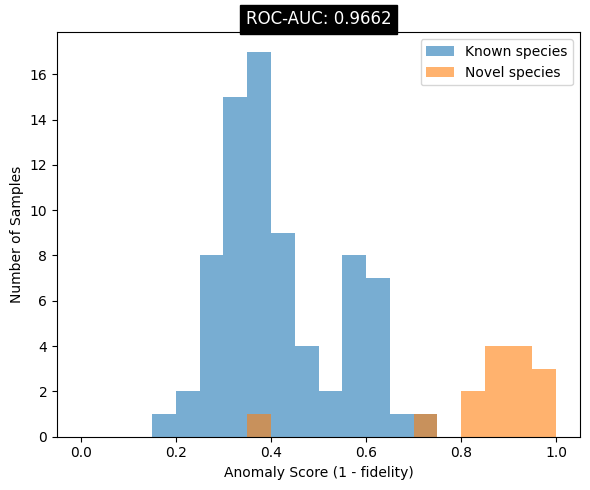

In [8]:
"""
Graphs: anomaly-score histogram + ROC-AUC for the QAE novel-species detector.
"""

import numpy as np
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt


def plot_anomaly_histogram(known_fidelities, novel_fidelities, roc_auc=None):
    known_scores = 1 - np.array(known_fidelities)
    novel_scores = 1 - np.array(novel_fidelities)

    bins = np.linspace(0, 1, 21)

    plt.figure(figsize=(6, 5))
    plt.hist(known_scores, bins=bins, alpha=0.6, label="Known species", color="tab:blue")
    plt.hist(novel_scores, bins=bins, alpha=0.6, label="Novel species", color="tab:orange")

    plt.xlabel("Anomaly Score (1 - fidelity)")
    plt.ylabel("Number of Samples")
    plt.legend()

    if roc_auc is not None:
        plt.title(f"ROC-AUC: {roc_auc}", fontsize=12, backgroundcolor="black", color="white")

    plt.tight_layout()
    plt.show()


if True:  # was: if __name__ == "__main__"
    weights = np.load("trained_weights.npy")

    # Same known-sequence refit as the scoring cell.
    known_seqs, _ = generate_known_samples(n_per_species=30)
    known_vectors, fitted = fit_feature_pipeline(known_seqs, k=3, n_qubits=N_QUBITS)

    # Held-out known + novel sets for evaluation.
    test_known_seqs, _ = generate_known_samples(n_per_species=15)
    test_novel_seqs = generate_novel_samples(n=15)

    test_known_vectors = transform_sequences(test_known_seqs, fitted)
    test_novel_vectors = transform_sequences(test_novel_seqs, fitted)

    known_fidelities = np.array([trash_fidelity(x, weights) for x in test_known_vectors])
    novel_fidelities = np.array([trash_fidelity(x, weights) for x in test_novel_vectors])

    # Labels: 0 = known, 1 = novel. Score: anomaly score = 1 - fidelity
    # (higher score => more anomalous => more likely novel).
    y_true = np.concatenate([np.zeros(len(known_fidelities)), np.ones(len(novel_fidelities))])
    y_score = np.concatenate([1 - known_fidelities, 1 - novel_fidelities])

    roc_auc = roc_auc_score(y_true, y_score)
    print(f"ROC-AUC: {roc_auc:.4f}")

    plot_anomaly_histogram(known_fidelities, novel_fidelities, roc_auc=round(roc_auc, 4))